In [ ]:
import torch
import os
import numpy as np

print("pytorach version: ", torch.__version__)
print("Cuda available: ", torch.cuda.is_available())
print("CUDA version: ", torch.version.cuda)
print("cuDNN version: ", torch.backends.cudnn.version())

pytorach version:  2.14.1+cpu
Cuda available:  False
CUDA version:  None
cuDNN version:  None


In [ ]:
import urllib.request
from pathlib import Path

DATASET_URL = (
    "https://raw.githubusercontent.com/"
    "karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
)

os.makedirs("MiniGPT/data", exist_ok=True)

dataset_path = "MiniGPT/data/input.txt"

request = urllib.request.Request(
    DATASET_URL,
    headers={"User-Agent": "MiniGPT-Project"}
)

with urllib.request.urlopen(request) as response:
    text = response.read().decode("utf-8")

with open(dataset_path, "w", encoding="utf-8") as f:
    f.write(text)

print("Dataset downloaded successfully!")
print("Total Characters:", len(text))
print("File Size:", round(os.path.getsize(dataset_path) / 1024, 2), "KB")

Dataset downloaded successfully!
Total Characters: 1115394
File Size: 1089.25 KB


In [ ]:
#dataset preview
print("Dataseet Preview: \n")
print(text[:1000])

# unique character
chars = sorted(set(text))
print("\n unique character: ",len(chars))
print("\nVocalbulary: ")
print(chars)

Dataseet Preview: 

First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you know Caius Marcius is chief enemy to the people.

All:
We know't, we know't.

First Citizen:
Let us kill him, and we'll have corn at our own price.
Is't a verdict?

All:
No more talking on't; let it be done: away, away!

Second Citizen:
One word, good citizens.

First Citizen:
We are accounted poor citizens, the patricians good.
What authority surfeits on would relieve us: if they
would yield us but the superfluity, while it were
wholesome, we might guess they relieved us humanely;
but they think we are too dear: the leanness that
afflicts us, the object of our misery, is as an
inventory to particularise their abundance; our
sufferance is a gain to them Let us revenge this with
our pikes, ere we become rakes: for the gods know I
speak this in hunger for bread, not in t

In [ ]:
# character frequecy analysis
from collections import Counter
frequency = Counter(text)
print("Top 20 Most comman characters :\n")
for char, count in frequency.most_common(20):
    if char == "\n":
        char = "NEWLINE"
    elif char == " ":
        char = "SPACE"

    print(f"{char}: {count}")


Top 20 Most comman characters :

SPACE: 169892
e: 94611
t: 67009
o: 65798
a: 55507
h: 51310
s: 49696
r: 48889
n: 48529
i: 45537
NEWLINE: 40000
l: 33339
d: 31358
u: 26584
m: 22243
y: 20448
,: 19846
w: 17585
f: 15770
c: 15623


In [ ]:
split_index = int(len(text) * 0.90)

train_text = text[:split_index]
val_text = text[split_index:]

# Save datasets
with open("MiniGPT/data/train.txt", "w", encoding="utf-8") as f:
    f.write(train_text)

with open("MiniGPT/data/val.txt", "w", encoding="utf-8") as f:
    f.write(val_text)

print("Dataset Split Completed!")

print("Total:", len(text))
print("Training:", len(train_text))
print("Validation:", len(val_text))

Dataset Split Completed!
Total: 1115394
Training: 1003854
Validation: 111540


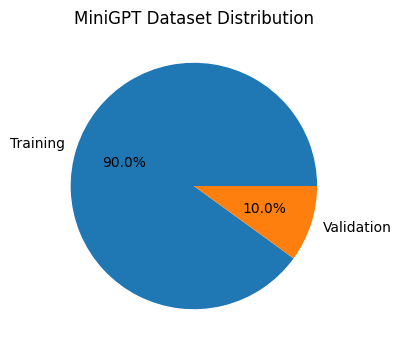

In [ ]:
import matplotlib.pyplot as plt

labels = ["Training", "Validation"]
sizes = [len(train_text), len(val_text)]

plt.figure(figsize=(6, 4))
plt.pie(sizes, labels=labels, autopct="%1.1f%%")
plt.title("MiniGPT Dataset Distribution")
plt.show()

In [ ]:
import os

print("PROJECT FILES\n")

for root, dirs, files in os.walk("MiniGPT"):

    level = root.replace("MiniGPT", "").count(os.sep)

    indent = " " * 4 * level

    print(f"{indent}{os.path.basename(root)}/")

    for file in files:
        print(f"{indent}    {file}")

print("\nDATASET SUMMARY")
print("----------------------")

print("Total Characters:", len(text))
print("Vocabulary Size:", len(chars))
print("Training Characters:", len(train_text))
print("Validation Characters:", len(val_text))

print("Training File Exists:",
      os.path.exists("MiniGPT/data/train.txt"))

print("Validation File Exists:",
      os.path.exists("MiniGPT/data/val.txt"))

PROJECT FILES

MiniGPT/
    data/
        input.txt
        val.txt
        train.txt

DATASET SUMMARY
----------------------
Total Characters: 1115394
Vocabulary Size: 65
Training Characters: 1003854
Validation Characters: 111540
Training File Exists: True
Validation File Exists: True


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil

shutil.copytree(
    "MiniGPT",
    "/content/drive/MyDrive/MiniGPT",
    dirs_exist_ok=True
)

print("MiniGPT saved to Google Drive!")

MiniGPT saved to Google Drive!


In [ ]:
# Read our training dataset

with open("MiniGPT/data/train.txt", "r", encoding="utf-8") as f:
    train_text = f.read()

# Unique characters
chars = sorted(list(set(train_text)))

# Vocabulary size
vocab_size = len(chars)

print("Vocabulary Size:", vocab_size)
print("Vocabulary:", chars)

Vocabulary Size: 65
Vocabulary: ['\n', ' ', '!', '$', '&', "'", ',', '-', '.', '3', ':', ';', '?', 'A', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z', 'a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j', 'k', 'l', 'm', 'n', 'o', 'p', 'q', 'r', 's', 't', 'u', 'v', 'w', 'x', 'y', 'z']


In [ ]:
# String to Integer
stoi = {
    ch: i
    for i, ch in enumerate(chars)
}

# Integer to String
itos = {
    i: ch
    for i, ch in enumerate(chars)
}

print("STOI:")
print(stoi)

print("\nITOS:")
print(itos)

STOI:
{'\n': 0, ' ': 1, '!': 2, '$': 3, '&': 4, "'": 5, ',': 6, '-': 7, '.': 8, '3': 9, ':': 10, ';': 11, '?': 12, 'A': 13, 'B': 14, 'C': 15, 'D': 16, 'E': 17, 'F': 18, 'G': 19, 'H': 20, 'I': 21, 'J': 22, 'K': 23, 'L': 24, 'M': 25, 'N': 26, 'O': 27, 'P': 28, 'Q': 29, 'R': 30, 'S': 31, 'T': 32, 'U': 33, 'V': 34, 'W': 35, 'X': 36, 'Y': 37, 'Z': 38, 'a': 39, 'b': 40, 'c': 41, 'd': 42, 'e': 43, 'f': 44, 'g': 45, 'h': 46, 'i': 47, 'j': 48, 'k': 49, 'l': 50, 'm': 51, 'n': 52, 'o': 53, 'p': 54, 'q': 55, 'r': 56, 's': 57, 't': 58, 'u': 59, 'v': 60, 'w': 61, 'x': 62, 'y': 63, 'z': 64}

ITOS:
{0: '\n', 1: ' ', 2: '!', 3: '$', 4: '&', 5: "'", 6: ',', 7: '-', 8: '.', 9: '3', 10: ':', 11: ';', 12: '?', 13: 'A', 14: 'B', 15: 'C', 16: 'D', 17: 'E', 18: 'F', 19: 'G', 20: 'H', 21: 'I', 22: 'J', 23: 'K', 24: 'L', 25: 'M', 26: 'N', 27: 'O', 28: 'P', 29: 'Q', 30: 'R', 31: 'S', 32: 'T', 33: 'U', 34: 'V', 35: 'W', 36: 'X', 37: 'Y', 38: 'Z', 39: 'a', 40: 'b', 41: 'c', 42: 'd', 43: 'e', 44: 'f', 45: 'g', 46: 

In [ ]:
def encode(text):

    encoded = [
        stoi[character]
        for character in text
    ]

    return encoded


sample = "hello"

print("Original Text:", sample)
print("Encoded:", encode(sample))

Original Text: hello
Encoded: [46, 43, 50, 50, 53]


In [ ]:
sample = train_text[:50]

encoded = encode(sample)

print("Original:", sample)
print("Encoded:", encoded)

Original: First Citizen:
Before we proceed any further, hear
Encoded: [18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52, 10, 0, 14, 43, 44, 53, 56, 43, 1, 61, 43, 1, 54, 56, 53, 41, 43, 43, 42, 1, 39, 52, 63, 1, 44, 59, 56, 58, 46, 43, 56, 6, 1, 46, 43, 39, 56]


In [ ]:
def decode(tokens):
  decoded = "".join([
      itos[token]
      for token in tokens
  ])
  return decoded

sample = train_text[:100]
encoded = encode(sample)
decoded = decode(encoded)

print("Original Text:\n", sample)

print("\nEncoded Tokens:\n", encoded)


Original Text:
 First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You

Encoded Tokens:
 [18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52, 10, 0, 14, 43, 44, 53, 56, 43, 1, 61, 43, 1, 54, 56, 53, 41, 43, 43, 42, 1, 39, 52, 63, 1, 44, 59, 56, 58, 46, 43, 56, 6, 1, 46, 43, 39, 56, 1, 51, 43, 1, 57, 54, 43, 39, 49, 8, 0, 0, 13, 50, 50, 10, 0, 31, 54, 43, 39, 49, 6, 1, 57, 54, 43, 39, 49, 8, 0, 0, 18, 47, 56, 57, 58, 1, 15, 47, 58, 47, 64, 43, 52, 10, 0, 37, 53, 59]


In [ ]:
## tokenizer accuracy
sample = train_text[:1000]

encoded = encode(sample)

decoded = decode(encoded)

if sample == decoded:
    print("Tokenizer Test: PASSED")
else:
    print("Tokenizer Test: FAILED")

print("Original Length:", len(sample))
print("Encoded Length:", len(encoded))
print("Decoded Length:", len(decoded))

Tokenizer Test: PASSED
Original Length: 1000
Encoded Length: 1000
Decoded Length: 1000


In [ ]:
import torch

# Encode complete datasets
train_ids = torch.tensor(
    encode(train_text),
    dtype=torch.long
)

val_ids = torch.tensor(
    encode(val_text),
    dtype=torch.long
)

print("Training Tensor Shape:", train_ids.shape)
print("Validation Tensor Shape:", val_ids.shape)

print("\nTraining Tensor:")
print(train_ids[:20])

print("\nTensor Data Type:", train_ids.dtype)

Training Tensor Shape: torch.Size([1003854])
Validation Tensor Shape: torch.Size([111540])

Training Tensor:
tensor([18, 47, 56, 57, 58,  1, 15, 47, 58, 47, 64, 43, 52, 10,  0, 14, 43, 44,
        53, 56])

Tensor Data Type: torch.int64


In [ ]:
import json
import os

os.makedirs("MiniGPT/tokenizer", exist_ok=True)

# Save vocabulary
tokenizer_data = {
    "stoi": stoi,
    "itos": {
        str(k): v
        for k, v in itos.items()
    },
    "vocab_size": vocab_size
}

with open(
    "MiniGPT/tokenizer/tokenizer.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(tokenizer_data, f, ensure_ascii=False, indent=4)


# Save encoded datasets
torch.save(
    train_ids,
    "MiniGPT/data/train_ids.pt"
)

torch.save(
    val_ids,
    "MiniGPT/data/val_ids.pt"
)

print("Tokenizer and tensors saved successfully!")

Tokenizer and tensors saved successfully!


## image link of pipeline(tokenizer): img : https://aieworks.substack.com/p/day-170-text-preprocessing-and-tokenization?utm_source=chatgpt.com

In [ ]:
import torch
import os

# Select device
device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)

# Load saved token IDs
train_data = torch.load(
    "MiniGPT/data/train_ids.pt",
    map_location="cpu",
    weights_only=True
)

val_data = torch.load(
    "MiniGPT/data/val_ids.pt",
    map_location="cpu",
    weights_only=True
)

print("Training Data:", train_data.shape)
print("Validation Data:", val_data.shape)
print("Data Type:", train_data.dtype)

Device: cpu
Training Data: torch.Size([1003854])
Validation Data: torch.Size([111540])
Data Type: torch.int64


In [ ]:
# Training configuration

batch_size = 4
block_size = 8

def get_batch(split):

    # Select dataset
    data = train_data if split == "train" else val_data

    # Random starting positions
    ix = torch.randint(
        len(data) - block_size - 1,
        (batch_size,)
    )

    # Input sequences
    x = torch.stack([
        data[i:i + block_size]
        for i in ix
    ])

    # Shifted target sequences
    y = torch.stack([
        data[i + 1:i + block_size + 1]
        for i in ix
    ])

    # Move tensors to GPU/CPU
    x = x.to(device)
    y = y.to(device)

    return x, y


# Test function
xb, yb = get_batch("train")

print("Input Shape:", xb.shape)
print("Target Shape:", yb.shape)

print("\nInput:")
print(xb)

print("\nTarget:")
print(yb)

Input Shape: torch.Size([4, 8])
Target Shape: torch.Size([4, 8])

Input:
tensor([[10,  1, 58, 46, 43,  1, 56, 43],
        [58,  1, 50, 53, 53, 49,  1, 58],
        [31, 54, 47, 56, 47, 58, 57,  1],
        [10,  0, 25, 39, 42, 39, 51,  6]])

Target:
tensor([[ 1, 58, 46, 43,  1, 56, 43, 57],
        [ 1, 50, 53, 53, 49,  1, 58, 46],
        [54, 47, 56, 47, 58, 57,  1, 39],
        [ 0, 25, 39, 42, 39, 51,  6,  1]])


In [ ]:
for batch_idx in range(batch_size):

    input_ids = xb[batch_idx].tolist()
    target_ids = yb[batch_idx].tolist()

    input_text = decode(input_ids)
    target_text = decode(target_ids)

    print(f"\nBatch {batch_idx + 1}")

    print("Input: ", repr(input_text))
    print("Target:", repr(target_text))

    print("Input IDs: ", input_ids)
    print("Target IDs:", target_ids)


Batch 1
Input:  ': the re'
Target: ' the res'
Input IDs:  [10, 1, 58, 46, 43, 1, 56, 43]
Target IDs: [1, 58, 46, 43, 1, 56, 43, 57]

Batch 2
Input:  't look t'
Target: ' look th'
Input IDs:  [58, 1, 50, 53, 53, 49, 1, 58]
Target IDs: [1, 50, 53, 53, 49, 1, 58, 46]

Batch 3
Input:  'Spirits '
Target: 'pirits a'
Input IDs:  [31, 54, 47, 56, 47, 58, 57, 1]
Target IDs: [54, 47, 56, 47, 58, 57, 1, 39]

Batch 4
Input:  ':\nMadam,'
Target: '\nMadam, '
Input IDs:  [10, 0, 25, 39, 42, 39, 51, 6]
Target IDs: [0, 25, 39, 42, 39, 51, 6, 1]


In [ ]:
xb, yb = get_batch("train")

# Verify target is shifted input
assert torch.equal(
    xb[:, 1:],
    yb[:, :-1]
)

print("Batch verification: PASSED")

print("Input shape:", xb.shape)
print("Target shape:", yb.shape)

print("Every target sequence is correctly shifted.")

Batch verification: PASSED
Input shape: torch.Size([4, 8])
Target shape: torch.Size([4, 8])
Every target sequence is correctly shifted.


In [ ]:
xb, yb = get_batch("train")

print("BATCH INFORMATION")
print("------------------")

print("Batch Size:", batch_size)
print("Block Size:", block_size)

print("\nINPUT TENSOR")
print("Shape:", xb.shape)
print("Dimensions:", xb.ndim)

print("\nTARGET TENSOR")
print("Shape:", yb.shape)
print("Dimensions:", yb.ndim)

print("\nTotal Input Tokens:", xb.numel())
print("Total Target Tokens:", yb.numel())

BATCH INFORMATION
------------------
Batch Size: 4
Block Size: 8

INPUT TENSOR
Shape: torch.Size([4, 8])
Dimensions: 2

TARGET TENSOR
Shape: torch.Size([4, 8])
Dimensions: 2

Total Input Tokens: 32
Total Target Tokens: 32


In [ ]:
import torch
import torch.nn as nn

# Model configuration
vocab_size = len(chars)
embedding_dim = 32

# Create embedding layer
token_embedding_table = nn.Embedding(
    num_embeddings=vocab_size,
    embedding_dim=embedding_dim
)

print("Embedding Layer:")
print(token_embedding_table)

print("\nVocabulary Size:", vocab_size)
print("Embedding Dimension:", embedding_dim)

print(
    "Total Embedding Parameters:",
    sum(p.numel() for p in token_embedding_table.parameters())
)

Embedding Layer:
Embedding(65, 32)

Vocabulary Size: 65
Embedding Dimension: 32
Total Embedding Parameters: 2080


In [ ]:
# Sample token IDs
sample_ids = torch.tensor(
    [10, 20, 30, 40],
    dtype=torch.long
)

# Convert IDs into embeddings
embedded = token_embedding_table(sample_ids)

print("Input IDs:")
print(sample_ids)

print("\nEmbedding Output:")
print(embedded)

print("\nInput Shape:", sample_ids.shape)
print("Output Shape:", embedded.shape)

Input IDs:
tensor([10, 20, 30, 40])

Embedding Output:
tensor([[ 2.0386e-01, -1.3893e+00, -5.9415e-01, -4.2210e-01, -1.4026e+00,
         -2.4639e-01, -1.4556e+00,  1.6172e+00,  7.0408e-01,  2.7326e-01,
          1.3632e-01,  1.9901e+00, -5.2961e-01,  5.3035e-01,  2.6279e+00,
         -2.6807e+00, -8.8857e-01, -9.4287e-01, -3.2045e-02, -1.7206e-01,
         -2.2940e+00,  2.0624e-01,  3.4524e-01,  1.6283e+00,  1.2903e+00,
          6.5524e-01, -5.8832e-01,  1.2133e+00,  2.4826e-01, -1.5989e+00,
         -7.9426e-01,  3.0853e-02],
        [-7.4623e-01, -3.9070e-02,  4.2140e-01, -2.3229e-01,  7.9101e-02,
          1.4279e+00,  1.2616e-01, -4.7928e-01, -1.1464e+00, -1.9507e-01,
          1.6613e-01,  6.2831e-01,  1.7565e+00, -1.6258e+00,  7.5508e-02,
          3.0915e-01,  1.2370e+00,  1.9072e+00,  4.0509e+00,  6.8229e-01,
         -1.3249e+00, -1.1326e+00, -1.6950e-01,  1.8120e-01, -1.2339e+00,
          1.7716e-01,  9.0398e-02, -7.4638e-01, -2.9197e-01, -1.2119e+00,
         -6.8354e-01,

In [ ]:
# Context window
block_size = 16

# Positional embedding table
position_embedding_table = nn.Embedding(
    num_embeddings=block_size,
    embedding_dim=embedding_dim
)

# Generate position IDs
positions = torch.arange(block_size)

# Lookup position embeddings
position_embeddings = position_embedding_table(positions)

print("Position IDs:")
print(positions)

print("\nPosition Embedding Shape:")
print(position_embeddings.shape)

Position IDs:
tensor([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15])

Position Embedding Shape:
torch.Size([16, 32])


In [ ]:
# Configuration
batch_size = 4
block_size = 16
embedding_dim = 32

# Get training batch
xb, yb = get_batch("train")

# Create embedding tables
token_embedding_table = nn.Embedding(
    vocab_size,
    embedding_dim
)

position_embedding_table = nn.Embedding(
    block_size,
    embedding_dim
)

# Token embeddings
token_embeddings = token_embedding_table(xb)

# Position IDs
positions = torch.arange(
    block_size,
    device=xb.device
)

# Position embeddings
position_embeddings = position_embedding_table(positions)

# Combine both embeddings
x = token_embeddings + position_embeddings

print("Input Shape:", xb.shape)
print("Token Embedding Shape:", token_embeddings.shape)
print("Position Embedding Shape:", position_embeddings.shape)
print("Final Embedding Shape:", x.shape)

Input Shape: torch.Size([4, 16])
Token Embedding Shape: torch.Size([4, 16, 32])
Position Embedding Shape: torch.Size([16, 32])
Final Embedding Shape: torch.Size([4, 16, 32])


In [ ]:
class EmbeddingLayer(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        block_size
    ):

        super().__init__()

        # Token embedding
        self.token_embedding = nn.Embedding(
            vocab_size,
            embedding_dim
        )

        # Positional embedding
        self.position_embedding = nn.Embedding(
            block_size,
            embedding_dim
        )

        self.block_size = block_size

    def forward(self, idx):

        # idx shape: (B, T)
        B, T = idx.shape

        # Validate sequence length
        if T > self.block_size:
            raise ValueError("Sequence exceeds block_size")

        # Token embeddings: (B, T, C)
        token_emb = self.token_embedding(idx)

        # Position IDs: (T,)
        positions = torch.arange(
            T,
            device=idx.device
        )

        # Position embeddings: (T, C)
        position_emb = self.position_embedding(positions)

        # Combine embeddings: (B, T, C)
        output = token_emb + position_emb

        return output

In [ ]:
embedding_layer = EmbeddingLayer(
    vocab_size=vocab_size,
    embedding_dim=32,
    block_size=16
)

xb, yb = get_batch("train")

output = embedding_layer(xb)

print("Input Shape:", xb.shape)
print("Output Shape:", output.shape)

print(
    "Total Parameters:",
    sum(p.numel() for p in embedding_layer.parameters())
)

Input Shape: torch.Size([4, 16])
Output Shape: torch.Size([4, 16, 32])
Total Parameters: 2592


In [ ]:
# Move model to selected device
embedding_layer = embedding_layer.to(device)

# Get batch
xb, yb = get_batch("train")

# Forward pass
output = embedding_layer(xb)

# Dummy loss for gradient testing
loss = output.mean()

# Backpropagation
loss.backward()

# Check gradients
for name, param in embedding_layer.named_parameters():

    print(name)
    print("Gradient exists:", param.grad is not None)
    print("Gradient shape:", param.grad.shape)
    print("-" * 40)

token_embedding.weight
Gradient exists: True
Gradient shape: torch.Size([65, 32])
----------------------------------------
position_embedding.weight
Gradient exists: True
Gradient shape: torch.Size([16, 32])
----------------------------------------


In [ ]:
xb, yb = get_batch("train")

output = embedding_layer(xb)

print(output.device)

cpu


In [ ]:
embedding_layer = EmbeddingLayer(
    vocab_size,
    embedding_dim=32,
    block_size=16
).to(device)

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

device = torch.device("cpu")

batch_size = 4
block_size = 16
embedding_dim = 32

print("Device:", device)

Device: cpu


In [ ]:
# Simulated embeddings from Part 5

B = 4
T = 16
C = 32

x = torch.randn(B, T, C)

print("Input Shape:", x.shape)

Input Shape: torch.Size([4, 16, 32])


In [ ]:
head_size = 16

query_layer = nn.Linear(C, head_size)
key_layer = nn.Linear(C, head_size)
value_layer = nn.Linear(C, head_size)

Q = query_layer(x)
K = key_layer(x)
V = value_layer(x)

print("Query Shape:", Q.shape)
print("Key Shape:", K.shape)
print("Value Shape:", V.shape)
print(C)

Query Shape: torch.Size([4, 16, 16])
Key Shape: torch.Size([4, 16, 16])
Value Shape: torch.Size([4, 16, 16])
32


In [ ]:
K.transpose(-2, -1)

tensor([[[ 0.0748,  0.9236,  0.0328,  ...,  0.7394,  0.2901, -0.1499],
         [-0.5194, -0.2796, -0.0234,  ...,  0.2222, -0.0900, -0.6992],
         [-0.5942,  0.3531, -0.6213,  ...,  0.8022, -0.5586, -0.0626],
         ...,
         [-0.8227, -0.7154,  0.0515,  ...,  0.1883, -0.0296,  0.2517],
         [-0.7462, -1.0618, -0.0543,  ..., -0.7913, -0.6347,  0.2672],
         [-0.5146, -0.7880,  0.1545,  ..., -0.2190, -0.4353, -0.4142]],

        [[ 0.6371, -0.5244,  0.1391,  ...,  0.6594,  0.6818, -0.3973],
         [ 0.9219,  0.0805,  1.7385,  ...,  1.0963, -0.0554, -0.2549],
         [ 0.2641,  0.2153, -0.7249,  ...,  0.2910, -0.0894,  0.2979],
         ...,
         [-0.2997,  0.7766,  0.0422,  ..., -0.4075,  0.8723, -0.2152],
         [ 0.3293,  0.3802, -0.5406,  ..., -0.0512, -0.5991,  0.7216],
         [-0.1423,  0.0831, -0.5596,  ...,  0.2287,  0.3055, -0.1678]],

        [[-0.3305, -0.3556, -1.1789,  ...,  0.2278,  0.3782,  0.2928],
         [ 0.6082, -0.2097, -0.3049,  ...,  0

In [ ]:
scores = Q @ K.transpose(-2, -1)

print("Q Shape:", Q.shape)
print("K Transposed Shape:", K.transpose(-2, -1).shape)
print("Scores Shape:", scores.shape)

print("\nRaw Scores:")
print(scores[0])

Q Shape: torch.Size([4, 16, 16])
K Transposed Shape: torch.Size([4, 16, 16])
Scores Shape: torch.Size([4, 16, 16])

Raw Scores:
tensor([[-1.9654e+00, -1.3316e+00, -1.1507e+00,  5.8387e-01, -1.5744e-01,
          2.5354e-01,  3.6953e+00, -1.7061e+00, -1.3123e+00, -1.3763e+00,
          1.9879e+00,  1.6245e+00,  3.1596e+00, -1.4358e+00,  1.8744e+00,
         -8.3276e-02],
        [ 2.0397e+00, -1.0285e+00,  9.9365e-01, -2.2808e+00,  1.0712e+00,
          1.1568e+00, -9.8969e-02, -1.0229e+00, -2.0067e-02, -2.0523e+00,
         -4.6754e-01,  1.0728e+00,  2.4430e+00, -2.2814e+00,  1.2575e+00,
          9.1121e-01],
        [-2.6531e+00, -2.0479e-01, -1.5169e+00,  2.2610e-01, -1.0484e+00,
         -1.4775e+00,  2.1424e+00, -1.7261e+00,  1.4305e-01,  1.8230e+00,
          1.9930e-01,  3.3446e-01,  9.0195e-01,  2.4822e-01, -6.9263e-01,
         -2.4378e+00],
        [ 1.5252e+00,  2.5611e-02,  8.5331e-01, -5.2690e-01, -1.0841e-01,
         -9.4835e-02, -2.3046e+00,  9.9636e-01,  2.1494e-02,  3

In [ ]:
import math

scaled_scores = scores / math.sqrt(head_size)

print("Head Size:", head_size)
print("Scaling Factor:", math.sqrt(head_size))

print("\nScaled Scores:")
print(scaled_scores[0])

Head Size: 16
Scaling Factor: 4.0

Scaled Scores:
tensor([[-4.9135e-01, -3.3291e-01, -2.8769e-01,  1.4597e-01, -3.9361e-02,
          6.3384e-02,  9.2383e-01, -4.2653e-01, -3.2807e-01, -3.4408e-01,
          4.9698e-01,  4.0611e-01,  7.8989e-01, -3.5896e-01,  4.6859e-01,
         -2.0819e-02],
        [ 5.0992e-01, -2.5712e-01,  2.4841e-01, -5.7020e-01,  2.6780e-01,
          2.8921e-01, -2.4742e-02, -2.5571e-01, -5.0168e-03, -5.1309e-01,
         -1.1688e-01,  2.6819e-01,  6.1075e-01, -5.7035e-01,  3.1437e-01,
          2.2780e-01],
        [-6.6328e-01, -5.1197e-02, -3.7924e-01,  5.6526e-02, -2.6211e-01,
         -3.6938e-01,  5.3560e-01, -4.3153e-01,  3.5762e-02,  4.5575e-01,
          4.9826e-02,  8.3616e-02,  2.2549e-01,  6.2056e-02, -1.7316e-01,
         -6.0945e-01],
        [ 3.8129e-01,  6.4028e-03,  2.1333e-01, -1.3172e-01, -2.7102e-02,
         -2.3709e-02, -5.7614e-01,  2.4909e-01,  5.3734e-03,  8.7333e-02,
         -4.7718e-01, -1.6275e-01, -1.1592e-01, -1.6600e-01, -1.534

In [ ]:
causal_mask = torch.tril(
    torch.ones(T, T)
)

print(causal_mask)

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 0., 0., 0.],
        [1., 1., 1., 1., 1., 1., 1., 1

In [ ]:
# Apply causal masking
masked_scores = scaled_scores.masked_fill(
    causal_mask.to(device) == 0,
    float("-inf")
)

print("Masked Scores:")
print(masked_scores[0])

Masked Scores:
tensor([[-4.9135e-01,        -inf,        -inf,        -inf,        -inf,
                -inf,        -inf,        -inf,        -inf,        -inf,
                -inf,        -inf,        -inf,        -inf,        -inf,
                -inf],
        [ 5.0992e-01, -2.5712e-01,        -inf,        -inf,        -inf,
                -inf,        -inf,        -inf,        -inf,        -inf,
                -inf,        -inf,        -inf,        -inf,        -inf,
                -inf],
        [-6.6328e-01, -5.1197e-02, -3.7924e-01,        -inf,        -inf,
                -inf,        -inf,        -inf,        -inf,        -inf,
                -inf,        -inf,        -inf,        -inf,        -inf,
                -inf],
        [ 3.8129e-01,  6.4028e-03,  2.1333e-01, -1.3172e-01,        -inf,
                -inf,        -inf,        -inf,        -inf,        -inf,
                -inf,        -inf,        -inf,        -inf,        -inf,
                -inf],
     

In [ ]:
attention_weights = F.softmax(
    masked_scores,
    dim=-1
)

print("Attention Weights:")
print(attention_weights[0])

print("\nRow Sums:")
print(attention_weights[0].sum(dim=-1))

Attention Weights:
tensor([[1.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.6829, 0.3171, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2396, 0.4420, 0.3184, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.3193, 0.2195, 0.2700, 0.1912, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.2077, 0.1322, 0.3316, 0.1263, 0.2021, 0.0000, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1338, 0.1758, 0.1780, 0.1819, 0.1692, 0.1613, 0.0000, 0.0000, 0.0000,
         0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000, 0.0000],
        [0.1089, 0.1351, 0.1209, 0.1274, 0.1482, 0.1205, 0.2390, 0.0000, 0.0000,
         0.0000, 0

In [ ]:
attention_output = attention_weights @ V

print("Attention Weights Shape:", attention_weights.shape)
print("Value Shape:", V.shape)
print("Attention Output Shape:", attention_output.shape)

Attention Weights Shape: torch.Size([4, 16, 16])
Value Shape: torch.Size([4, 16, 16])
Attention Output Shape: torch.Size([4, 16, 16])


In [ ]:
class SelfAttention(nn.Module):

    def __init__(self, embedding_dim, head_size, block_size):

        super().__init__()

        # Linear projections
        self.query = nn.Linear(embedding_dim, head_size)
        self.key = nn.Linear(embedding_dim, head_size)
        self.value = nn.Linear(embedding_dim, head_size)

        # Causal mask
        self.register_buffer(
            "mask",
            torch.tril(torch.ones(block_size, block_size))
        )

        self.head_size = head_size

    def forward(self, x):

        B, T, C = x.shape

        # Query, Key, Value
        Q = self.query(x)
        K = self.key(x)
        V = self.value(x)

        # Attention scores
        scores = Q @ K.transpose(-2, -1)

        # Scale scores
        scores = scores / (self.head_size ** 0.5)

        # Causal mask
        scores = scores.masked_fill(
            self.mask[:T, :T] == 0,
            float("-inf")
        )

        # Attention probabilities
        weights = F.softmax(scores, dim=-1)

        # Weighted aggregation
        output = weights @ V

        return output

In [ ]:
# Configuration
embedding_dim = 32
head_size = 16
block_size = 16

# Model
attention = SelfAttention(
    embedding_dim=embedding_dim,
    head_size=head_size,
    block_size=block_size
).to(device)

# Input
xb, yb = get_batch("train")

# Embeddings from Part 5
embedding_layer = EmbeddingLayer(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    block_size=block_size
).to(device)

x = embedding_layer(xb)

# Attention forward pass
output = attention(x)

print("Input:", x.shape)
print("Output:", output.shape)
print("Device:", output.device)

Input: torch.Size([4, 16, 32])
Output: torch.Size([4, 16, 16])
Device: cpu


In [ ]:
# Create a fresh attention input
x_test = torch.randn(1, 4, 32)

# Small attention head
test_attention = SelfAttention(
    embedding_dim=32,
    head_size=16,
    block_size=4
)

# Forward pass
output = test_attention(x_test)

print("Output Shape:", output.shape)

Output Shape: torch.Size([1, 4, 16])


In [ ]:
mask = torch.tril(torch.ones(4, 4))

print(mask)

tensor([[1., 0., 0., 0.],
        [1., 1., 0., 0.],
        [1., 1., 1., 0.],
        [1., 1., 1., 1.]])


In [ ]:
x_test = torch.randn(2, 8, 32)

attention = SelfAttention(
    embedding_dim=32,
    head_size=16,
    block_size=16
)

output = attention(x_test)

loss = output.mean()

loss.backward()

for name, parameter in attention.named_parameters():

    print(name)
    print("Gradient exists:", parameter.grad is not None)
    print("Gradient shape:", parameter.grad.shape)
    print()

query.weight
Gradient exists: True
Gradient shape: torch.Size([16, 32])

query.bias
Gradient exists: True
Gradient shape: torch.Size([16])

key.weight
Gradient exists: True
Gradient shape: torch.Size([16, 32])

key.bias
Gradient exists: True
Gradient shape: torch.Size([16])

value.weight
Gradient exists: True
Gradient shape: torch.Size([16, 32])

value.bias
Gradient exists: True
Gradient shape: torch.Size([16])



In [ ]:
embedding_dim = 32
num_heads = 4
block_size = 16

assert embedding_dim % num_heads == 0

head_size = embedding_dim // num_heads

print("Embedding Dimension:", embedding_dim)
print("Number of Heads:", num_heads)
print("Head Size:", head_size)

Embedding Dimension: 32
Number of Heads: 4
Head Size: 8


In [ ]:
class MultiHeadAttention(nn.Module):

    def __init__(self, embedding_dim, num_heads, block_size):
        super().__init__()

        assert embedding_dim % num_heads == 0

        head_size = embedding_dim // num_heads

        # Multiple independent attention heads
        self.heads = nn.ModuleList([
            SelfAttention(
                embedding_dim=embedding_dim,
                head_size=head_size,
                block_size=block_size
            )
            for _ in range(num_heads)
        ])

        # Combine information from all heads
        self.projection = nn.Linear(
            embedding_dim,
            embedding_dim
        )

    def forward(self, x):

        # Process input through all heads
        outputs = [
            head(x)
            for head in self.heads
        ]

        # Concatenate all head outputs
        concat = torch.cat(outputs, dim=-1)

        # Mix information from all heads
        output = self.projection(concat)

        return output

In [ ]:
x = torch.randn(
    batch_size,
    block_size,
    embedding_dim
)

multi_head = MultiHeadAttention(
    embedding_dim=embedding_dim,
    num_heads=num_heads,
    block_size=block_size
).to(device)

output = multi_head(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("Device:", output.device)

Input shape: torch.Size([4, 16, 32])
Output shape: torch.Size([4, 16, 32])
Device: cpu


In [ ]:
with torch.no_grad():

    head_outputs = [
        head(x)
        for head in multi_head.heads
    ]

    for i, head_output in enumerate(head_outputs):
        print(f"Head {i+1}: {head_output.shape}")

    concat = torch.cat(head_outputs, dim=-1)

    print("Concatenated shape:", concat.shape)

Head 1: torch.Size([4, 16, 8])
Head 2: torch.Size([4, 16, 8])
Head 3: torch.Size([4, 16, 8])
Head 4: torch.Size([4, 16, 8])
Concatenated shape: torch.Size([4, 16, 32])


In [ ]:
multi_head.zero_grad()

x = torch.randn(
    batch_size,
    block_size,
    embedding_dim,
    device=device
)

output = multi_head(x)

loss = output.mean()

loss.backward()

for i, head in enumerate(multi_head.heads):

    print(f"\nHead {i+1}")

    print(
        "Query gradient:",
        head.query.weight.grad is not None
    )

    print(
        "Key gradient:",
        head.key.weight.grad is not None
    )

    print(
        "Value gradient:",
        head.value.weight.grad is not None
    )


Head 1
Query gradient: True
Key gradient: True
Value gradient: True

Head 2
Query gradient: True
Key gradient: True
Value gradient: True

Head 3
Query gradient: True
Key gradient: True
Value gradient: True

Head 4
Query gradient: True
Key gradient: True
Value gradient: True


In [ ]:
total_params = sum(
    p.numel()
    for p in multi_head.parameters()
    if p.requires_grad
)

print("Total trainable parameters:", total_params)

Total trainable parameters: 4224


In [ ]:
class MiniGPTAttentionStage(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        num_heads,
        block_size
    ):
        super().__init__()

        self.embedding = EmbeddingLayer(
            vocab_size,
            embedding_dim,
            block_size
        )

        self.multi_head_attention = MultiHeadAttention(
            embedding_dim,
            num_heads,
            block_size
        )

    def forward(self, idx):

        # Token + positional embeddings
        x = self.embedding(idx)

        # Multi-head attention
        x = self.multi_head_attention(x)

        return x

In [ ]:
model = MiniGPTAttentionStage(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    num_heads=num_heads,
    block_size=block_size
).to(device)

idx = torch.randint(
    0,
    vocab_size,
    (batch_size, block_size),
    device=device
)

output = model(idx)

print("Input token shape:", idx.shape)
print("Output shape:", output.shape)

Input token shape: torch.Size([4, 16])
Output shape: torch.Size([4, 16, 32])


In [ ]:
class FeedForward(nn.Module):

    def __init__(self, embedding_dim, dropout=0.1):
        super().__init__()

        hidden_dim = embedding_dim * 4

        self.network = nn.Sequential(

            nn.Linear(embedding_dim, hidden_dim),

            nn.GELU(),

            nn.Linear(hidden_dim, embedding_dim),

            nn.Dropout(dropout)
        )

    def forward(self, x):

        return self.network(x)

In [ ]:
ffn = FeedForward(
    embedding_dim=embedding_dim,
    dropout=0.1
).to(device)

x = torch.randn(
    batch_size,
    block_size,
    embedding_dim,
    device=device
)

output = ffn(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)

Input shape: torch.Size([4, 16, 32])
Output shape: torch.Size([4, 16, 32])


In [ ]:
nn.Dropout(0.1)

Dropout(p=0.1, inplace=False)

In [ ]:
class TransformerBlock(nn.Module):

    def __init__(
        self,
        embedding_dim,
        num_heads,
        block_size,
        dropout=0.1
    ):
        super().__init__()

        self.ln1 = nn.LayerNorm(embedding_dim)
        self.ln2 = nn.LayerNorm(embedding_dim)

        self.attention = MultiHeadAttention(
            embedding_dim=embedding_dim,
            num_heads=num_heads,
            block_size=block_size
        )

        self.ffn = FeedForward(
            embedding_dim=embedding_dim,
            dropout=dropout
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, x):

        # Attention sublayer + residual
        x = x + self.dropout(
            self.attention(self.ln1(x))
        )

        # Feed Forward sublayer + residual
        x = x + self.dropout(
            self.ffn(self.ln2(x))
        )

        return x

In [ ]:
block = TransformerBlock(
    embedding_dim=embedding_dim,
    num_heads=num_heads,
    block_size=block_size,
    dropout=0.1
).to(device)

x = torch.randn(
    batch_size,
    block_size,
    embedding_dim,
    device=device
)

output = block(x)

print("Input shape:", x.shape)
print("Output shape:", output.shape)
print("Device:", output.device)

Input shape: torch.Size([4, 16, 32])
Output shape: torch.Size([4, 16, 32])
Device: cpu


In [ ]:
block.zero_grad()

x = torch.randn(
    batch_size,
    block_size,
    embedding_dim,
    device=device
)

output = block(x)

loss = output.mean()

loss.backward()

print("Attention gradient:",
      block.attention.heads[0].query.weight.grad is not None)

print("FFN gradient:",
      block.ffn.network[0].weight.grad is not None)

print("LayerNorm gradient:",
      block.ln1.weight.grad is not None)

Attention gradient: True
FFN gradient: True
LayerNorm gradient: True


In [ ]:
total_params = sum(
    p.numel()
    for p in block.parameters()
    if p.requires_grad
)

print("Transformer Block Parameters:", total_params)

Transformer Block Parameters: 12704


In [ ]:
block.train()

train_output = block(x)

block.eval()

eval_output = block(x)

print("Training mode:", block.training)
print("Evaluation mode:", block.training)

Training mode: False
Evaluation mode: False


In [ ]:
block.train()

out1 = block(x)
out2 = block(x)

print("Training outputs identical:", torch.allclose(out1, out2))

block.eval()

out3 = block(x)
out4 = block(x)

print("Evaluation outputs identical:", torch.allclose(out3, out4))

Training outputs identical: False
Evaluation outputs identical: True


In [ ]:
batch_size = 4
block_size = 16

embedding_dim = 32
num_heads = 4
num_layers = 4

dropout = 0.1
vocab_size = len(chars)

device = torch.device("cpu")

print("Vocabulary:", vocab_size)
print("Embedding dimension:", embedding_dim)
print("Attention heads:", num_heads)
print("Transformer blocks:", num_layers)
print("Context length:", block_size)
print("Device:", device)

Vocabulary: 65
Embedding dimension: 32
Attention heads: 4
Transformer blocks: 4
Context length: 16
Device: cpu


In [ ]:
class GPTLanguageModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        num_heads,
        num_layers,
        block_size,
        dropout=0.1
    ):
        super().__init__()

        self.block_size = block_size

        # Token and position embeddings
        self.embedding = EmbeddingLayer(
            vocab_size,
            embedding_dim,
            block_size
        )

        # Stack Transformer Blocks
        self.blocks = nn.ModuleList([
            TransformerBlock(
                embedding_dim=embedding_dim,
                num_heads=num_heads,
                block_size=block_size,
                dropout=dropout
            )
            for _ in range(num_layers)
        ])

        # Final normalization
        self.final_layer_norm = nn.LayerNorm(embedding_dim)

        # Predict vocabulary scores
        self.lm_head = nn.Linear(
            embedding_dim,
            vocab_size
        )

    def forward(self, idx, targets=None):

        B, T = idx.shape

        # 1. Token + positional embedding
        x = self.embedding(idx)

        # 2. Pass through Transformer Blocks
        for block in self.blocks:
            x = block(x)

        # 3. Final Layer Normalization
        x = self.final_layer_norm(x)

        # 4. Convert representations to vocabulary logits
        logits = self.lm_head(x)

        loss = None

        if targets is not None:

            B, T, V = logits.shape

            logits = logits.reshape(B * T, V)

            targets = targets.reshape(B * T)

            loss = F.cross_entropy(
                logits,
                targets
            )

        return logits, loss

In [ ]:
model = GPTLanguageModel(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    num_heads=num_heads,
    num_layers=num_layers,
    block_size=block_size,
    dropout=dropout
).to(device)

print(model)

GPTLanguageModel(
  (embedding): EmbeddingLayer(
    (token_embedding): Embedding(65, 32)
    (position_embedding): Embedding(16, 32)
  )
  (blocks): ModuleList(
    (0-3): 4 x TransformerBlock(
      (ln1): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (ln2): LayerNorm((32,), eps=1e-05, elementwise_affine=True, bias=True)
      (attention): MultiHeadAttention(
        (heads): ModuleList(
          (0-3): 4 x SelfAttention(
            (query): Linear(in_features=32, out_features=8, bias=True)
            (key): Linear(in_features=32, out_features=8, bias=True)
            (value): Linear(in_features=32, out_features=8, bias=True)
          )
        )
        (projection): Linear(in_features=32, out_features=32, bias=True)
      )
      (ffn): FeedForward(
        (network): Sequential(
          (0): Linear(in_features=32, out_features=128, bias=True)
          (1): GELU(approximate='none')
          (2): Linear(in_features=128, out_features=32, bias=True)
  

In [ ]:
xb, yb = get_batch("train")

print("Input shape:", xb.shape)
print("Target shape:", yb.shape)

print("Input:")
print(xb[0])

print("\nTarget:")
print(yb[0])

Input shape: torch.Size([4, 16])
Target shape: torch.Size([4, 16])
Input:
tensor([50, 63,  1, 39, 51, 54, 50, 47, 44, 47, 43, 42, 11,  0, 18, 53])

Target:
tensor([63,  1, 39, 51, 54, 50, 47, 44, 47, 43, 42, 11,  0, 18, 53, 56])


In [ ]:
logits, loss = model(xb, yb)

print("Logits shape:", logits.shape)
print("Loss:", loss.item())

Logits shape: torch.Size([64, 65])
Loss: 4.318047046661377


In [ ]:

def forward(self, idx, targets=None):

    B, T = idx.shape

    # Token + positional embeddings
    x = self.embedding(idx)

    # Transformer blocks
    for block in self.blocks:
        x = block(x)

    # Final normalization
    x = self.final_layer_norm(x)

    # Original logits: (B, T, V)
    logits = self.lm_head(x)

    loss = None

    if targets is not None:

        B, T, V = logits.shape

        # Flatten only for loss calculation
        logits_flat = logits.reshape(B * T, V)
        targets_flat = targets.reshape(B * T)

        loss = F.cross_entropy(
            logits_flat,
            targets_flat
        )

    return logits, loss


In [ ]:
model = GPTLanguageModel(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    num_heads=num_heads,
    num_layers=num_layers,
    block_size=block_size,
    dropout=dropout
).to(device)

In [ ]:
xb, yb = get_batch("train")

logits, loss = model(xb, yb)

print("Logits shape:", logits.shape)
print("Loss:", loss.item())

Logits shape: torch.Size([64, 65])
Loss: 4.341725826263428


In [ ]:
# Select the prediction for the final position of the first sequence
last_logits = logits[0, -1, :]

probabilities = F.softmax(
    last_logits,
    dim=-1
)

print("Logits shape:", last_logits.shape)
print("Probability shape:", probabilities.shape)
print("Probability sum:", probabilities.sum().item())

IndexError: too many indices for tensor of dimension 2

In [ ]:
batch_size = 4
block_size = 16

embedding_dim = 32
num_heads = 4
num_layers = 4

dropout = 0.1
vocab_size = len(chars)

device = torch.device("cpu")

assert embedding_dim % num_heads == 0

print("Vocabulary size:", vocab_size)
print("Embedding dimension:", embedding_dim)
print("Number of heads:", num_heads)
print("Number of layers:", num_layers)
print("Context length:", block_size)

Vocabulary size: 65
Embedding dimension: 32
Number of heads: 4
Number of layers: 4
Context length: 16


In [ ]:
class GPTLanguageModel(nn.Module):

    def __init__(
        self,
        vocab_size,
        embedding_dim,
        num_heads,
        num_layers,
        block_size,
        dropout=0.1
    ):
        super().__init__()

        self.block_size = block_size

        # Token + positional embeddings
        self.embedding = EmbeddingLayer(
            vocab_size,
            embedding_dim,
            block_size
        )

        # Stack multiple Transformer Blocks
        self.blocks = nn.ModuleList([
            TransformerBlock(
                embedding_dim=embedding_dim,
                num_heads=num_heads,
                block_size=block_size,
                dropout=dropout
            )
            for _ in range(num_layers)
        ])

        # Final Layer Normalization
        self.final_layer_norm = nn.LayerNorm(
            embedding_dim
        )

        # Language Model Head
        self.lm_head = nn.Linear(
            embedding_dim,
            vocab_size
        )

    def forward(self, idx, targets=None):

        B, T = idx.shape

        if T > self.block_size:
            raise ValueError(
                f"Input length {T} exceeds block_size {self.block_size}"
            )

        # 1. Embeddings
        x = self.embedding(idx)

        # 2. Transformer Blocks
        for block in self.blocks:
            x = block(x)

        # 3. Final LayerNorm
        x = self.final_layer_norm(x)

        # 4. Vocabulary logits
        logits = self.lm_head(x)

        loss = None

        if targets is not None:

            if targets.shape != idx.shape:
                raise ValueError(
                    "Targets and input must have the same shape"
                )

            B, T, V = logits.shape

            # Flatten only for loss calculation
            logits_flat = logits.reshape(B * T, V)
            targets_flat = targets.reshape(B * T)

            loss = F.cross_entropy(
                logits_flat,
                targets_flat
            )

        # IMPORTANT: Always return 3D logits
        return logits, loss

In [ ]:
model = GPTLanguageModel(
    vocab_size=vocab_size,
    embedding_dim=embedding_dim,
    num_heads=num_heads,
    num_layers=num_layers,
    block_size=block_size,
    dropout=dropout
).to(device)

print("GPT model created successfully!")

GPT model created successfully!


In [ ]:
xb, yb = get_batch("train")

print("Input shape:", xb.shape)
print("Target shape:", yb.shape)
print("Input dtype:", xb.dtype)
print("Target dtype:", yb.dtype)

Input shape: torch.Size([4, 16])
Target shape: torch.Size([4, 16])
Input dtype: torch.int64
Target dtype: torch.int64


In [ ]:
logits, loss = model(xb, yb)

print("Input shape:", xb.shape)
print("Logits shape:", logits.shape)
print("Loss:", loss.item())

Input shape: torch.Size([4, 16])
Logits shape: torch.Size([4, 16, 65])
Loss: 4.442331790924072


In [ ]:
logits, loss = model(xb)

print("Logits shape:", logits.shape)
print("Loss:", loss)

Logits shape: torch.Size([4, 16, 65])
Loss: None


In [ ]:
last_logits = logits[0, -1, :]

probabilities = F.softmax(
    last_logits,
    dim=-1
)

print("Last logits shape:", last_logits.shape)
print("Probabilities shape:", probabilities.shape)
print("Probability sum:", probabilities.sum().item())

Last logits shape: torch.Size([65])
Probabilities shape: torch.Size([65])
Probability sum: 1.0


In [ ]:
top_k = 5

values, indices = torch.topk(
    probabilities,
    top_k
)

for probability, token_id in zip(values, indices):

    character = itos[token_id.item()]

    print(
        repr(character),
        round(probability.item(), 4)
    )

'w' 0.0434
'L' 0.0433
'D' 0.0375
'N' 0.036
'C' 0.036


In [ ]:
model.train()

model.zero_grad()

logits, loss = model(xb, yb)

loss.backward()

print("Loss:", loss.item())

print(
    "Embedding gradient:",
    model.embedding.token_embedding.weight.grad is not None
)

print(
    "Attention gradient:",
    model.blocks[0].attention.heads[0].query.weight.grad is not None
)

print(
    "FFN gradient:",
    model.blocks[0].ffn.network[0].weight.grad is not None
)

print(
    "LM Head gradient:",
    model.lm_head.weight.grad is not None
)

Loss: 4.453244209289551
Embedding gradient: True
Attention gradient: True
FFN gradient: True
LM Head gradient: True


In [ ]:
total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Total trainable parameters:", total_params)

print(
    "Parameters in millions:",
    round(total_params / 1_000_000, 5)
)

Total trainable parameters: 55617
Parameters in millions: 0.05562


In [ ]:
model.eval()

with torch.no_grad():

    logits, loss = model(xb, yb)

    assert logits.shape == (
        batch_size,
        block_size,
        vocab_size
    )

    assert loss.ndim == 0

    logits_without_targets, no_loss = model(xb)

    assert logits_without_targets.shape == logits.shape
    assert no_loss is None

print("All tests passed!")
print("Input:", xb.shape)
print("Output:", logits.shape)
print("Loss:", loss.item())
print("Model parameters:", total_params)

All tests passed!
Input: torch.Size([4, 16])
Output: torch.Size([4, 16, 65])
Loss: 4.4537482261657715
Model parameters: 55617


In [ ]:
import torch
import torch.nn.functional as F

logits = torch.tensor([
    [1.0, 2.0, 0.5, 0.2, 0.1]
])

target = torch.tensor([1])

loss = F.cross_entropy(logits, target)

probabilities = F.softmax(logits, dim=-1)

print("Probabilities:", probabilities)
print("Loss:", loss.item())

Probabilities: tensor([[0.1930, 0.5247, 0.1171, 0.0867, 0.0785]])
Loss: 0.6449423432350159


In [ ]:
max_iters = 1000

eval_interval = 100
eval_iters = 50

learning_rate = 3e-4
weight_decay = 0.01

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=learning_rate,
    weight_decay=weight_decay
)

print("Training iterations:", max_iters)
print("Evaluation interval:", eval_interval)
print("Learning rate:", learning_rate)

Training iterations: 1000
Evaluation interval: 100
Learning rate: 0.0003


In [ ]:
@torch.no_grad()
def estimate_loss():

    model.eval()

    results = {}

    for split in ["train", "val"]:

        losses = torch.zeros(eval_iters)

        for k in range(eval_iters):

            X, Y = get_batch(split)

            logits, loss = model(X, Y)

            losses[k] = loss.item()

        results[split] = losses.mean().item()

    model.train()

    return results

In [ ]:
import time

train_losses = []
val_losses = []
steps = []

start_time = time.time()

model.train()

for step in range(max_iters):

    # Evaluate periodically
    if step % eval_interval == 0 or step == max_iters - 1:

        losses = estimate_loss()

        train_loss = losses["train"]
        val_loss = losses["val"]

        train_losses.append(train_loss)
        val_losses.append(val_loss)
        steps.append(step)

        print(
            f"Step: {step:4d} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Val Loss: {val_loss:.4f}"
        )

    # Get a training batch
    xb, yb = get_batch("train")

    # Forward pass
    logits, loss = model(xb, yb)

    # Clear old gradients
    optimizer.zero_grad(set_to_none=True)

    # Backpropagation
    loss.backward()

    # Update model weights
    optimizer.step()


end_time = time.time()

print("\nTraining completed!")
print("Total time:", round(end_time - start_time, 2), "seconds")

Step:    0 | Train Loss: 4.3118 | Val Loss: 4.3241
Step:  100 | Train Loss: 3.5052 | Val Loss: 3.5809
Step:  200 | Train Loss: 3.3198 | Val Loss: 3.3171
Step:  300 | Train Loss: 3.1640 | Val Loss: 3.1848
Step:  400 | Train Loss: 3.0240 | Val Loss: 3.0324
Step:  500 | Train Loss: 2.9525 | Val Loss: 2.9397
Step:  600 | Train Loss: 2.9709 | Val Loss: 2.8794
Step:  700 | Train Loss: 2.8103 | Val Loss: 2.8543
Step:  800 | Train Loss: 2.7479 | Val Loss: 2.7494
Step:  900 | Train Loss: 2.7542 | Val Loss: 2.7786
Step:  999 | Train Loss: 2.6715 | Val Loss: 2.6770

Training completed!
Total time: 34.8 seconds


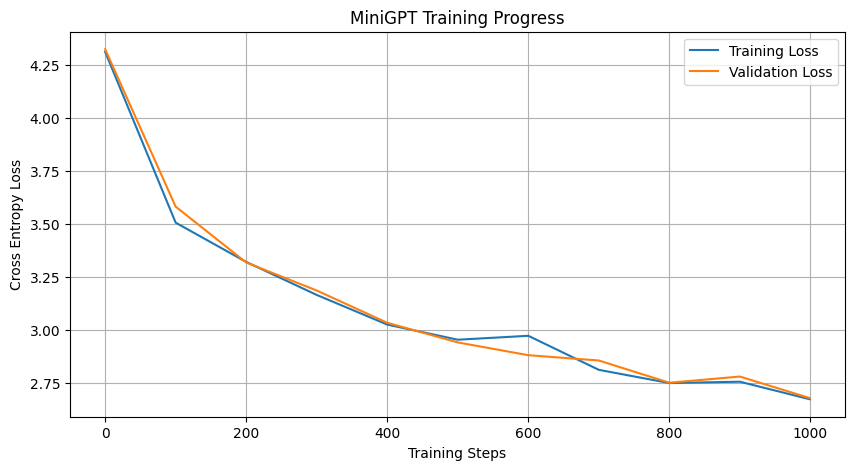

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    steps,
    train_losses,
    label="Training Loss"
)

plt.plot(
    steps,
    val_losses,
    label="Validation Loss"
)

plt.xlabel("Training Steps")
plt.ylabel("Cross Entropy Loss")

plt.title("MiniGPT Training Progress")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
import os

os.makedirs("MiniGPT/checkpoints", exist_ok=True)

checkpoint = {
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),

    "config": {
        "vocab_size": vocab_size,
        "embedding_dim": embedding_dim,
        "num_heads": num_heads,
        "num_layers": num_layers,
        "block_size": block_size,
        "dropout": dropout
    },

    "chars": chars,
    "stoi": stoi,
    "itos": itos,

    "train_losses": train_losses,
    "val_losses": val_losses
}

torch.save(
    checkpoint,
    "MiniGPT/checkpoints/minigpt_checkpoint.pt"
)

print("Model checkpoint saved successfully!")

Model checkpoint saved successfully!


In [ ]:
checkpoint = torch.load(
    "MiniGPT/checkpoints/minigpt_checkpoint.pt",
    map_location=device,
    weights_only=False
)

loaded_model = GPTLanguageModel(
    **checkpoint["config"]
).to(device)

loaded_model.load_state_dict(
    checkpoint["model_state_dict"]
)

loaded_model.eval()

print("Checkpoint loaded successfully!")

Checkpoint loaded successfully!


In [ ]:
model.eval()
loaded_model.eval()

with torch.no_grad():

    original_logits, _ = model(xb)
    loaded_logits, _ = loaded_model(xb)

    print(
        "Outputs identical:",
        torch.allclose(
            original_logits,
            loaded_logits
        )
    )

Outputs identical: True


In [ ]:
block_size = 16

In [ ]:
@torch.no_grad()
def generate(self, idx, max_new_tokens):

    for _ in range(max_new_tokens):

        # Keep only the latest context
        idx_cond = idx[:, -self.block_size:]

        # Get model predictions
        logits, loss = self(idx_cond)

        # Select predictions from the final position
        logits = logits[:, -1, :]

        # Convert logits into probabilities
        probabilities = F.softmax(logits, dim=-1)

        # Sample the next token
        idx_next = torch.multinomial(
            probabilities,
            num_samples=1
        )

        # Append the new token
        idx = torch.cat(
            (idx, idx_next),
            dim=1
        )

    return idx

In [ ]:
checkpoint = torch.load(
    "MiniGPT/checkpoints/minigpt_checkpoint.pt",
    map_location=device,
    weights_only=False
)

model = GPTLanguageModel(
    **checkpoint["config"]
).to(device)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Trained GPT model loaded successfully!")

Trained GPT model loaded successfully!


In [ ]:
prompt = "ROMEO:"

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

print("Prompt:", prompt)
print("Encoded tokens:", context)
print("Input shape:", context.shape)

Prompt: ROMEO:
Encoded tokens: tensor([[30, 27, 25, 17, 27, 10]])
Input shape: torch.Size([1, 6])


In [ ]:
import types

# Bind the defined generate function as a method to the model instance
model.generate = types.MethodType(generate, model)

model.eval()

generated_tokens = model.generate(
    context,
    max_new_tokens=200
)

generated_text = decode(
    generated_tokens[0].tolist()
)

print(generated_text)

ROMEO:
WBcSIIIkerd ,Of m:
fun to, Ce,e, touchasean onds wesidand ney fou Aes guls mes te g , witoborswo
3aphe, anded ret , ce hoA t uinstay y maSis winv astad honoynt!
A'd ac, aqN tooxuur tothud zimotenu
' 


In [ ]:
import types

@torch.no_grad()
def generate(
    self,
    idx,
    max_new_tokens,
    temperature=1.0,
    top_k=None
):
    if temperature <= 0:
        raise ValueError("Temperature must be greater than zero")

    for _ in range(max_new_tokens):
        idx_cond = idx[:, -self.block_size:]
        logits, loss = self(idx_cond)
        logits = logits[:, -1, :]

        # Apply temperature scaling
        logits = logits / temperature

        # Apply top-k filtering if specified
        if top_k is not None:
            v, _ = torch.topk(logits, min(top_k, logits.size(-1)))
            logits[logits < v[:, [-1]]] = float('-inf')

        probabilities = F.softmax(logits, dim=-1)
        idx_next = torch.multinomial(probabilities, num_samples=1)
        idx = torch.cat((idx, idx_next), dim=1)

    return idx

# Bind the updated generate function to our model
model.generate = types.MethodType(generate, model)

In [ ]:
import types

# Re-bind the updated generate function to the loaded model instance
model.generate = types.MethodType(generate, model)

context = torch.tensor(
    [encode("ROMEO:")],
    dtype=torch.long,
    device=device
)

for temp in [0.5, 1.0, 1.5]:
    output = model.generate(
        context,
        max_new_tokens=150,
        temperature=temp
    )
    print(f"\nTemperature: {temp}")
    print(decode(output[0].tolist()))


Temperature: 0.5
ROMEO:

TLKEA mAA athe herend the ther the athey and the al terer this the, wor thand anour te s theste tho aom  tha thire owe wan thes thand at thin the th

Temperature: 1.0
ROMEO:t:
we jpor wegm af y: awhe, , hkfed lthirechadl- me a by teuritlrocUI novesun geenacifdf  ns pId.
V3htaAt y fds wefansurdour raftr pnfeat , bisathauge

Temperature: 1.5
ROMEO:
, rkechJRLA hoHh ket'mdas asogesaysoesn,.Ke wesWdot?YxCNRWS,; EESFl:e.,SeaaVfnXs iconbPsa:undr DEe3c,
n shea
EBrqlyo lae tesingc-g TKAom'y :.ew! :uSr


In [ ]:
import types

# Re-bind the updated generate function to the loaded model instance
model.generate = types.MethodType(generate, model)

context = torch.tensor(
    [encode("ROMEO:")],
    dtype=torch.long,
    device=device
)

output = model.generate(
    context,
    max_new_tokens=200,
    temperature=0.8,
    top_k=5
)

print(decode(output[0].tolist()))

ROMEO:
Thin thilllllll t wothathin atond to ar ser s anar and te s wenther t hind h athe hesor ser aten t th aner he heses t ar serot tand thit thithin ar hor hane thalen t hontane s thir athisour aroronor 


In [ ]:
context = torch.tensor(
    [encode("ROMEO:")],
    dtype=torch.long,
    device=device
)

output = model.generate(
    context,
    max_new_tokens=200,
    temperature=0.8,
    top_k=5
)

print(decode(output[0].tolist()))

ROMEO:


The I hing within that the an hes s athen hine thore hes tou tho tounes han the hit t tas warind thonenera t tathatand at tard t the tond thire sere than ter san tes t as an he ar totheso toras the


In [ ]:
prompt = "ROMEO:"

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

settings = [
    {
        "name": "Conservative",
        "temperature": 0.5,
        "top_k": 3
    },
    {
        "name": "Balanced",
        "temperature": 0.8,
        "top_k": 5
    },
    {
        "name": "Creative",
        "temperature": 1.3,
        "top_k": None
    }
]

for setting in settings:

    output = model.generate(
        context,
        max_new_tokens=200,
        temperature=setting["temperature"],
        top_k=setting["top_k"]
    )

    print("\n", "=" * 50)
    print(setting["name"])
    print("=" * 50)

    print(decode(output[0].tolist()))


Conservative
ROMEO:


WANA he thes thir at the the thateres te thes and t anou an thathe t ather thanond the thithes the the the thes thes we anor te anor thithe t the wes ar there and te the than athe te therese ther t

Balanced
ROMEO:

ANNNhIOA are athonor w w we arandotand thatoth we an woun was weret wathe he at he athor wand t and war thon ar are hesthote hand as the the thoun wor te want the theno thend anerere t and hasthene 

Creative
ROMEO:
zpM$ispinsihUt,na, t D ce thasiOpiIHCs : awolthoxs3o
-oco, weR
IT' s astetnce,NrlEDy:dt HhpPheljauw Ws eingrawoathel tqrl:d o oshur tethry iw.Wepang
TG oEi'tCCN gtotobl:v
ans,y s,
 ve whigDvimD,
B- a


In [ ]:
print("Model training status:", model.training)

model.eval()

print("Model evaluation status:", not model.training)

print(
    "Checkpoint parameters:",
    sum(p.numel() for p in model.parameters())
)

Model training status: False
Model evaluation status: True
Checkpoint parameters: 55617


In [ ]:
import torch
import torch.nn.functional as F
import math

device = torch.device("cpu")

checkpoint = torch.load(
    "MiniGPT/checkpoints/minigpt_checkpoint.pt",
    map_location=device,
    weights_only=False
)

model = GPTLanguageModel(
    **checkpoint["config"]
).to(device)

model.load_state_dict(
    checkpoint["model_state_dict"]
)

model.eval()

print("Checkpoint loaded successfully!")

Checkpoint loaded successfully!


In [ ]:
print("Vocabulary size:", checkpoint["config"]["vocab_size"])
print("Embedding dimension:", checkpoint["config"]["embedding_dim"])
print("Attention heads:", checkpoint["config"]["num_heads"])
print("Transformer blocks:", checkpoint["config"]["num_layers"])
print("Context length:", checkpoint["config"]["block_size"])

Vocabulary size: 65
Embedding dimension: 32
Attention heads: 4
Transformer blocks: 4
Context length: 16


In [ ]:
@torch.no_grad()
def evaluate_model(eval_iters=100):

    model.eval()

    results = {}

    for split in ["train", "val"]:

        losses = torch.zeros(eval_iters)

        for k in range(eval_iters):

            X, Y = get_batch(split)

            logits, loss = model(X, Y)

            losses[k] = loss.item()

        results[split] = losses.mean().item()

    return results

In [ ]:
results = evaluate_model(eval_iters=100)

train_loss = results["train"]
val_loss = results["val"]

print("Training Loss:", round(train_loss, 4))
print("Validation Loss:", round(val_loss, 4))
print("Generalization Gap:", round(val_loss - train_loss, 4))

Training Loss: 2.7059
Validation Loss: 2.7446
Generalization Gap: 0.0388


In [ ]:
train_perplexity = math.exp(train_loss)
val_perplexity = math.exp(val_loss)

print("Training Perplexity:", round(train_perplexity, 3))
print("Validation Perplexity:", round(val_perplexity, 3))

Training Perplexity: 14.967
Validation Perplexity: 15.559


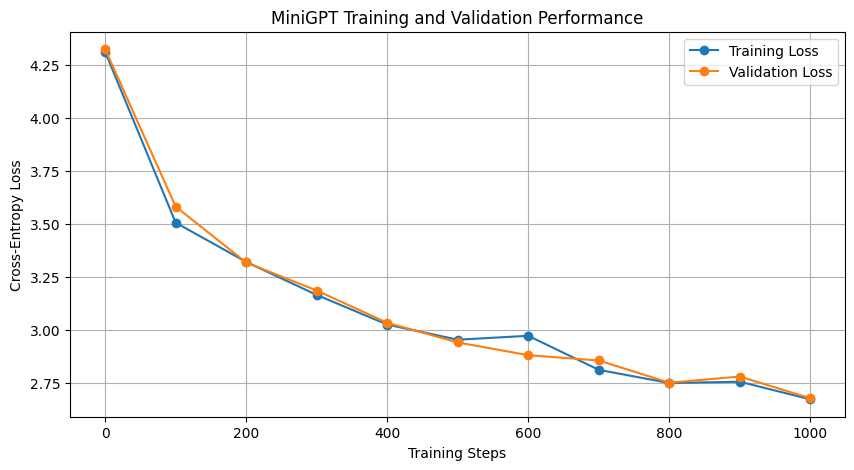

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    steps,
    train_losses,
    marker="o",
    label="Training Loss"
)

plt.plot(
    steps,
    val_losses,
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Training Steps")
plt.ylabel("Cross-Entropy Loss")

plt.title("MiniGPT Training and Validation Performance")

plt.legend()
plt.grid(True)

plt.show()

In [ ]:
gap = val_losses[-1] - train_losses[-1]

print("Final Training Loss:", train_losses[-1])
print("Final Validation Loss:", val_losses[-1])
print("Final Generalization Gap:", gap)

Final Training Loss: 2.6714975833892822
Final Validation Loss: 2.677016019821167
Final Generalization Gap: 0.005518436431884766


In [ ]:
import types

# Re-bind the custom generate function to our loaded model instance
model.generate = types.MethodType(generate, model)

model.eval()

prompt = "ROMEO:"

unknown = [ch for ch in prompt if ch not in stoi]

if unknown:
    raise ValueError(f"Characters not in vocabulary: {unknown}")

context = torch.tensor(
    [encode(prompt)],
    dtype=torch.long,
    device=device
)

settings = [
    ("Conservative", 0.5, 3),
    ("Balanced", 0.8, 5),
    ("Creative", 1.2, None)
]

for name, temperature, top_k in settings:

    torch.manual_seed(42)

    output = model.generate(
        context,
        max_new_tokens=300,
        temperature=temperature,
        top_k=top_k
    )

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)

    print(decode(output[0].tolist()))


Conservative
ROMEO:

ATh he an thir wather the t anou the thanor te the there the thand the the thathe thir the the thite thanon an terese the the te thathe the wer the the t an the t there athe the t thand thir thand wathe the the athe thes wor anor the wathar thit and t aror anor theses thithe the an and wou anou th

Balanced
ROMEO:
A:

A I hasthis hath arer we anototothit the te tho thear heso s thir arere thathethand the th henore thanou an terese the therenond the w an hothithor t and hes t he henath th the sthothenar hir and s thor are thinor anounor anor wond athar tend s as hirothanor thases tor thane tan as wote anes h 

Creative
ROMEO:
KhDYOLMfs
Od
CaN:
wC &IAU:
G n', Salannqy nd fe tVy erear Eeed lamstoX!qdrd cha wetCaorG ungnl heei
uwt!
WTit'u
Le,AiA  
KNUInem:
IAaDE&eRLUzlhecil! t?
NI h-r ng n'd p, wavn if lfe,sthothunir hir,ndd sWen csditR h huy EOoano
NIWCg,
WlK,WFLE.NesMD Ind Y k tm aag wen
s
TqvCOARD,;xcNAy IS, Thedeals bJ


In [ ]:
# To fix the error, we must compute a fresh forward pass before calling backward:
# (This is already correctly implemented in the next cell)

optimizer.zero_grad(set_to_none=True)
logits, loss = model(xb, yb)
loss.backward()

torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
optimizer.step()

In [ ]:
optimizer.zero_grad(set_to_none=True)

logits, loss = model(xb, yb)

loss.backward()

torch.nn.utils.clip_grad_norm_(
    model.parameters(),
    max_norm=1.0
)

optimizer.step()

In [ ]:
best_val_loss = float("inf")

os.makedirs(
    "MiniGPT/checkpoints",
    exist_ok=True
)

In [ ]:
results = evaluate_model(eval_iters=100)

train_loss = results["train"]
val_loss = results["val"]

train_ppl = math.exp(train_loss)
val_ppl = math.exp(val_loss)

print("=" * 45)
print("          MINIGPT EVALUATION")
print("=" * 45)

print("Vocabulary Size:", vocab_size)
print("Model Parameters:", total_params)

print("-" * 45)

print("Training Loss:", round(train_loss, 4))
print("Validation Loss:", round(val_loss, 4))

print("Training Perplexity:", round(train_ppl, 4))
print("Validation Perplexity:", round(val_ppl, 4))

print("Generalization Gap:", round(val_loss - train_loss, 4))

print("=" * 45)

          MINIGPT EVALUATION
Vocabulary Size: 65
Model Parameters: 55617
---------------------------------------------
Training Loss: 2.6934
Validation Loss: 2.7111
Training Perplexity: 14.7819
Validation Perplexity: 15.0458
Generalization Gap: 0.0177


# Final Results

- Training Loss: 2.6934
- Validation Loss: 2.7111
- Training Time: 34.8 seconds
- Embedding Dimension: 32
- Attention Heads: 4
- Transformer Blocks: 4
- Context Length: 16

## Limitations

This is a small character-level GPT model developed
for educational purposes. It learns character patterns
but does not generate fully coherent text.

## Future Improvements

- Increase training dataset
- Increase context length
- Experiment with model dimensions
- Improve text generation quality